# F3 — Prévision de l'inflation (Maroc)

**Nom et prénom :** Salmane Khaoula    **Code Apogée :** 23009361    **Groupe :** 3    **Filière :** S7 FIN    **Date :** 17/11/2026

**Dépôt GitHub :** https://github.com/salmane-khaoulaencg-a11y/23009361-Salmane-Khaoula-G3-FIN

## 1. Sujet et problématique
- **Intérêt du sujet** : l'inflation est suivie de près par Bank Al-Maghrib (fixation du taux directeur), par les entreprises (prix, salaires, contrats indexés) et par les investisseurs (taux, pouvoir d'achat). Savoir si un modèle simple apporte quelque chose de plus qu'une règle naïve aide à décider quelle prévision utiliser à court terme.
- **Problématique** : une régression Ridge construite sur les retards de l'inflation et de l'inflation sous-jacente permet-elle de prévoir l'inflation marocaine à horizon d'un mois mieux qu'une marche aléatoire (« ce mois = le mois précédent ») ?
- **Objectif mesurable** : métrique principale = **MAE** (erreur absolue moyenne, en points de pourcentage). Référence = marche aléatoire. Période de test = **2024-01 → 2026-09 (33 mois)**. Seuil de réussite, fixé avant de lire les résultats : **MAE de Ridge ≤ 85 % de la MAE de la marche aléatoire** (réduction d'au moins 15 %). Métriques secondaires : RMSE et R² hors échantillon par rapport à la marche aléatoire.
- **Nature du problème** : **régression sur série temporelle mensuelle** (cible continue, observations ordonnées dans le temps ; prévision à un pas).
- **Algorithme principal** : **n° 2 — Ridge** (annexe A).

In [1]:
# ---------- Configuration : imports, graine, chemins relatifs ----------
import sys, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
GRAINE = 42
np.random.seed(GRAINE)

# Racine du dépôt : le notebook peut être lancé depuis la racine, depuis notebooks/ ou depuis Colab
RACINE = Path.cwd()
if RACINE.name == "notebooks":
    RACINE = RACINE.parent
DOSSIER_BRUT, DOSSIER_PREP, DOSSIER_FIG = RACINE/"data"/"raw", RACINE/"data"/"processed", RACINE/"figures"
for dossier in (DOSSIER_PREP, DOSSIER_FIG):
    dossier.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

def sauver(nom):
    """Enregistre la figure courante dans figures/ (réutilisée pour le rapport et les diapositives)."""
    plt.savefig(DOSSIER_FIG/f"{nom}.png", dpi=150, bbox_inches="tight")

print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)
print("Racine du dépôt :", RACINE.name)

Python 3.12.3 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2
Racine du dépôt : repo


## 2. Jeu de données
Le chargement, le nettoyage et les contrôles sont faits dans les cellules ci-dessous ; la description complète vient ensuite.

In [2]:
# ---------- Chargement du fichier brut ----------
candidats = list(DOSSIER_BRUT.glob("BKAM*.xlsx")) or list(RACINE.glob("BKAM*.xlsx"))
assert candidats, "Fichier BKAM*.xlsx introuvable : le placer dans data/raw/"
FICHIER = candidats[0]
brut = pd.read_excel(FICHIER)
print("Fichier :", FICHIER.name)
print("Dimensions brutes :", brut.shape)
print("\nTypes bruts :"); print(brut.dtypes)
print("\nValeurs de la colonne Inflation stockées en texte (avant nettoyage) :")
print([repr(v) for v in brut.iloc[:, 1] if isinstance(v, str)])
display(brut.head(5))

Fichier : BKAM Inflation et inflation sous jacente.xlsx
Dimensions brutes : (105, 3)

Types bruts :
Mois                      datetime64[us]
Inflation                         object
Inflation sous-jacente           float64
dtype: object

Valeurs de la colonne Inflation stockées en texte (avant nettoyage) :
["'\\xa00,4'", "'\\xa00,4'"]


,Mois,Inflation,Inflation sous-jacente
0,2018-01-01,2,1.305221
1,2018-02-01,1.4,1.002004
2,2018-03-01,1.7,1.102204
3,2018-04-01,2.2,1.203611
4,2018-05-01,2.4,1.404213


In [3]:
# ---------- Nettoyage ----------
df = brut.copy()
df.columns = ["Mois", "Inflation", "Inflation_sous_jacente"]

# (1) Décimales : certaines cellules sont du texte avec virgule et espace insécable (ex. "\xa00,4")
for col in ["Inflation", "Inflation_sous_jacente"]:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace("\xa0", "", regex=False).str.strip()
                                   .str.replace(",", ".", regex=False))

# (2) Dates : à partir de 2023 le jour est incohérent (2023-02-02, 2023-05-30, 2024-01-05...).
#     Le MOIS reste correct : on le vérifie, puis on reconstruit un index mensuel régulier (1er du mois).
mois_brut = pd.to_datetime(brut["Mois"]).dt.to_period("M")
mois_reconstruits = pd.period_range("2018-01", periods=len(df), freq="M")
assert (mois_brut.values == mois_reconstruits.values).all(), "Mois non consécutifs : vérifier le fichier"
nb_dates_corrigees = int((pd.to_datetime(brut["Mois"]).dt.day != 1).sum())
df["Mois"] = mois_reconstruits.to_timestamp()

# (3) Contrôles de qualité
assert df["Mois"].is_unique and df["Mois"].is_monotonic_increasing
assert not df.isna().any().any()
print(f"Dates dont le jour était incohérent (corrigées au 1er du mois) : {nb_dates_corrigees}")
print("Dimensions :", df.shape, "| période :", df['Mois'].min().date(), "→", df['Mois'].max().date(), "| fréquence : mensuelle")
print("\nValeurs manquantes (%) :"); print((df.isna().mean()*100).round(1).to_string())
print("Doublons de date :", int(df['Mois'].duplicated().sum()))
display(df.head(4)); display(df.tail(4))

Dates dont le jour était incohérent (corrigées au 1er du mois) : 22
Dimensions : (105, 3) | période : 2018-01-01 → 2026-09-01 | fréquence : mensuelle

Valeurs manquantes (%) :
Mois                      0.0
Inflation                 0.0
Inflation_sous_jacente    0.0
Doublons de date : 0


,Mois,Inflation,Inflation_sous_jacente
0,2018-01-01,2.0,1.305221
1,2018-02-01,1.4,1.002004
2,2018-03-01,1.7,1.102204
3,2018-04-01,2.2,1.203611


,Mois,Inflation,Inflation_sous_jacente
101,2026-06-01,0.3,-0.2
102,2026-07-01,-0.6,-0.3
103,2026-08-01,-0.3,-0.1
104,2026-09-01,0.5,0.5


### Description du jeu de données

| Élément | Détail |
|---|---|
| **Nom** | « BKAM Inflation et inflation sous jacente.xlsx » (feuille `Feuil2`) |
| **Source** | Bank Al-Maghrib (BAM), rubrique Statistiques → Prix, qui publie l'inflation (indice des prix à la consommation, issu du Haut-Commissariat au Plan) et l'inflation sous-jacente |
| **Lien** | https://www.bkam.ma/Statistiques/Prix |
| **Date d'extraction** | 17/11/2026 (date d'utilisation du fichier ; la date exacte de téléchargement n'est pas inscrite dans le fichier) |
| **Licence** | Aucune licence ni condition de réutilisation n'est indiquée dans le fichier. Les conditions du site BAM sont à vérifier avant de redistribuer le fichier dans un dépôt public. |
| **Taille** | 105 observations × 3 variables (102 lignes exploitables après création des retards) |
| **Période / fréquence** | janvier 2018 → septembre 2026, mensuelle |
| **Unité d'observation** | un mois calendaire |
| **Variable cible** | `Inflation` du mois *t* : taux d'inflation **en glissement annuel** (variation de l'indice sur 12 mois, en %). Les niveaux observés (par exemple 10,1 % en février 2023) montrent que ce n'est pas une variation d'un mois sur l'autre. |

**Dictionnaire des variables**

| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| `Mois` | mois calendaire (reconstruit au 1er du mois) | date | — | date | 0 |
| `Inflation` | inflation, glissement annuel | numérique | % | **cible** (et source des retards) | 0 |
| `Inflation_sous_jacente` | inflation sous-jacente, glissement annuel (indicateur BAM excluant les produits à prix volatils et réglementés) | numérique | % | source de `Sous_jacente_lag1` | 0 |
| `Inflation_lag1`, `_lag2`, `_lag3` | inflation connue 1, 2, 3 mois plus tôt : `Inflation.shift(k)` | numérique | % | explicative | 0 (3 premiers mois retirés) |
| `Sous_jacente_lag1` | `Inflation_sous_jacente.shift(1)` | numérique | % | explicative | 0 (1er mois retiré) |
| `Tendance` | numéro d'ordre du mois : `0, 1, 2, …` | numérique | mois | explicative (jeu A seulement) | 0 |
| `Variation` | `Inflation − Inflation_lag1` | numérique | points de % | cible alternative apprise par Ridge | 0 |

**Adéquation.** Série officielle, mensuelle, sans valeur manquante, qui contient exactement ce qu'il faut pour une prévision à un mois : l'historique de l'inflation et un indicateur de tendance de fond.

**Limites.**
- Série courte (105 mois) ; seulement 69 observations pour l'apprentissage.
- Deux régimes : un choc très marqué en 2022-2023 (maximum de 10,1 %) dans l'apprentissage, puis une inflation faible (et une inflation sous-jacente négative d'octobre 2025 à août 2026) dans le test.
- Qualité du fichier : 22 dates avec un jour incohérent et 2 valeurs stockées en texte avec virgule (corrigées ci-dessous) ; précision hétérogène (certaines valeurs arrondies à 0,1, d'autres avec beaucoup de décimales, probablement recalculées).
- Un taux en glissement annuel recouvre 12 mois : la série est mécaniquement très persistante et soumise à des effets de base. L'indice mensuel, qui permettrait de les traiter, n'est pas dans le fichier.
- Révisions : le fichier n'indique ni la version publiée ni la base de l'indice ; on ne peut pas exclure de petits écarts avec les valeurs publiées en temps réel (limite à signaler selon la règle sur les révisions).

## 3. Exploration
Les statistiques et les graphiques 2 et 3 portent sur la période d'**apprentissage** (2018-01 → 2023-12). Le graphique 1 montre toute la série, la période de test étant grisée.

In [4]:
# ---------- Période d'apprentissage / de test (fixée avant toute analyse) ----------
DEBUT_TEST = pd.Timestamp("2024-01-01")
apprentissage = df[df["Mois"] < DEBUT_TEST]
print(f"Apprentissage brut : {apprentissage['Mois'].min():%Y-%m} → {apprentissage['Mois'].max():%Y-%m} ({len(apprentissage)} mois)")
print(f"Test brut          : {DEBUT_TEST:%Y-%m} → {df['Mois'].max():%Y-%m} ({(df['Mois'] >= DEBUT_TEST).sum()} mois)")

Apprentissage brut : 2018-01 → 2023-12 (72 mois)
Test brut          : 2024-01 → 2026-09 (33 mois)


In [5]:
# ---------- Exploration : statistiques sur la période d'APPRENTISSAGE uniquement ----------
exp = df[df["Mois"] < DEBUT_TEST].set_index("Mois")
print("Statistiques descriptives (apprentissage, en %) :")
display(exp[["Inflation", "Inflation_sous_jacente"]].describe().round(2))

# Valeurs atypiques : règles des 3 écarts-types et 1,5 × IQR (détection uniquement, aucune suppression)
z = (exp["Inflation"] - exp["Inflation"].mean()) / exp["Inflation"].std()
q1, q3 = exp["Inflation"].quantile([.25, .75]); iqr = q3 - q1
hors_iqr = exp[(exp["Inflation"] > q3 + 1.5*iqr) | (exp["Inflation"] < q1 - 1.5*iqr)]
print(f"\nMois à plus de 3 écarts-types : {int((z.abs() > 3).sum())} | hors règle 1,5×IQR : {len(hors_iqr)}")
display(hors_iqr[["Inflation", "Inflation_sous_jacente"]].round(2))

# Autocorrélations (niveau et variation mensuelle de l'inflation), apprentissage
niveau = exp["Inflation"]; variation = niveau.diff().dropna()
acf_niveau = [niveau.autocorr(k) for k in range(1, 13)]
acf_var = [variation.autocorr(k) for k in range(1, 13)]
print("\nAutocorrélation d'ordre 1 : niveau =", round(acf_niveau[0], 2), "| variation =", round(acf_var[0], 2))
print("Autocorrélation du niveau au retard 12 :", round(acf_niveau[11], 2), "| de la variation au retard 12 (effet de base) :", round(acf_var[11], 2))
print("Inflation sur la période de test : min =", df.loc[df['Mois'] >= DEBUT_TEST, 'Inflation'].min(), "| max =", df.loc[df['Mois'] >= DEBUT_TEST, 'Inflation'].max())

Statistiques descriptives (apprentissage, en %) :


,Inflation,Inflation_sous_jacente
count,72.00,72.00
mean,2.78,2.69
std,2.91,2.57
min,-0.70,0.20
25%,0.48,0.79
50%,1.60,1.50
75%,4.90,4.31
max,10.10,8.60



Mois à plus de 3 écarts-types : 0 | hors règle 1,5×IQR : 0


,Inflation,Inflation_sous_jacente
Mois,,



Autocorrélation d'ordre 1 : niveau = 0.97 | variation = 0.21
Autocorrélation du niveau au retard 12 : 0.42 | de la variation au retard 12 (effet de base) : -0.43
Inflation sur la période de test : min = -0.8 | max = 2.6


**Interprétation (statistiques et qualité).** Sur l'apprentissage (72 mois, 2018-01 → 2023-12), l'inflation a une moyenne de 2,78 % et une médiane de 1,60 % : la moyenne est tirée vers le haut par la flambée de 2022-2023 (maximum 10,10 %). Aucun mois n'est détecté comme atypique, ni par la règle des 3 écarts-types, ni par la règle 1,5 × IQR. Décision : **aucune valeur supprimée**. Les valeurs élevées forment une période continue de plusieurs mois (un choc réel), pas des erreurs isolées. Les 2 valeurs en texte et les 22 jours de date incohérents sont corrigés (voir section 2) ; il n'y a ni valeur manquante ni doublon.

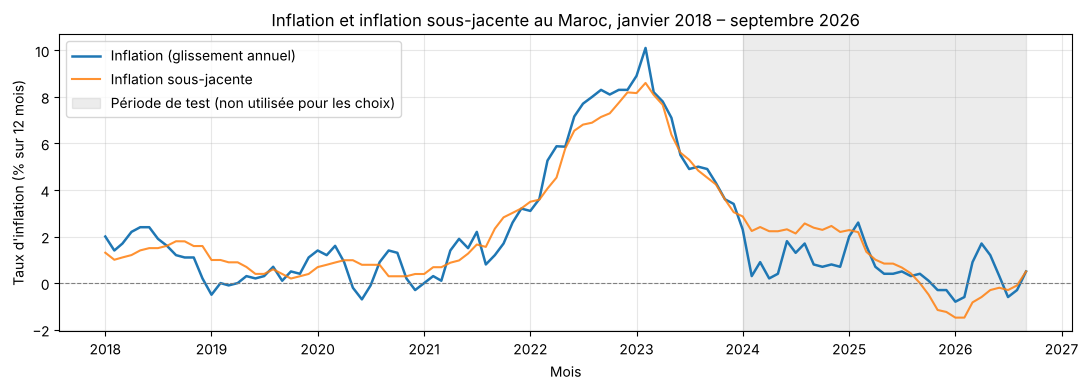

In [6]:
# ---------- Graphique 1 : évolution des deux séries (zone de test grisée à titre d'information) ----------
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df["Mois"], df["Inflation"], label="Inflation (glissement annuel)", color="#1f77b4", lw=1.8)
ax.plot(df["Mois"], df["Inflation_sous_jacente"], label="Inflation sous-jacente", color="#ff7f0e", lw=1.5, alpha=.85)
ax.axvspan(DEBUT_TEST, df["Mois"].max(), color="grey", alpha=.15, label="Période de test (non utilisée pour les choix)")
ax.axhline(0, color="grey", ls="--", lw=.8)
ax.set_title("Inflation et inflation sous-jacente au Maroc, janvier 2018 – septembre 2026")
ax.set_xlabel("Mois"); ax.set_ylabel("Taux d'inflation (% sur 12 mois)"); ax.legend(loc="upper left")
plt.tight_layout(); sauver("g1_evolution"); plt.show()

**Interprétation du graphique 1.** L'inflation reste faible jusqu'en 2021, monte à partir de fin 2021, atteint 10,1 % en février 2023, puis redescend. L'inflation sous-jacente suit le même mouvement, un peu en retard et moins heurtée. La zone grisée (test) montre un changement de régime : inflation entre −0,8 % et 2,6 %, sous-jacente négative d'octobre 2025 à août 2026. Cette zone n'est montrée qu'à titre d'information : aucune statistique ni aucun choix de préparation n'en est tiré.

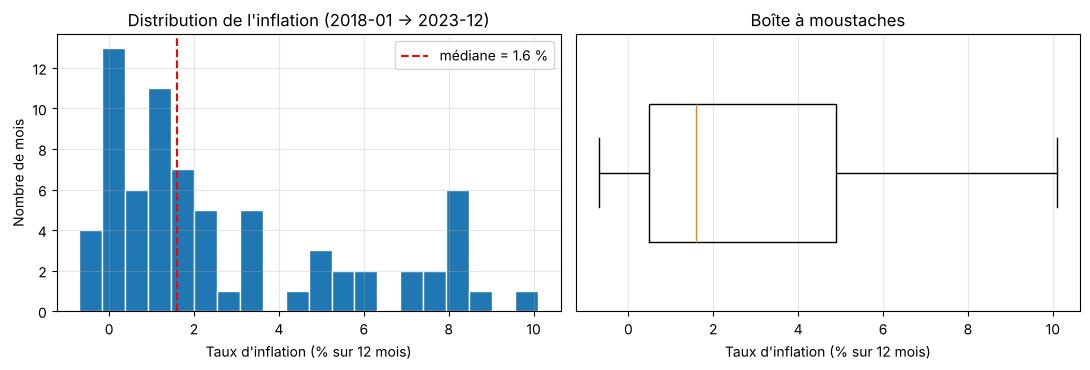

Asymétrie (skewness) : 0.96


In [7]:
# ---------- Graphique 2 : distribution de l'inflation (apprentissage) ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(exp["Inflation"], bins=20, color="#1f77b4", edgecolor="white")
axes[0].axvline(exp["Inflation"].median(), color="red", ls="--", label=f"médiane = {exp['Inflation'].median():.1f} %")
axes[0].set_title("Distribution de l'inflation (2018-01 → 2023-12)")
axes[0].set_xlabel("Taux d'inflation (% sur 12 mois)"); axes[0].set_ylabel("Nombre de mois"); axes[0].legend()
axes[1].boxplot(exp["Inflation"], vert=False, widths=.5)
axes[1].set_title("Boîte à moustaches"); axes[1].set_xlabel("Taux d'inflation (% sur 12 mois)"); axes[1].set_yticks([])
plt.tight_layout(); sauver("g2_distribution"); plt.show()
print("Asymétrie (skewness) :", round(exp["Inflation"].skew(), 2))

**Interprétation du graphique 2.** La distribution est asymétrique à droite (asymétrie de 0,96) : beaucoup de mois entre 0 et 3 %, et une queue vers 8-10 % qui correspond à 2022-2023. La boîte à moustaches ne signale aucun point isolé, ce qui confirme que ces valeurs élevées font partie d'un régime et non d'anomalies.

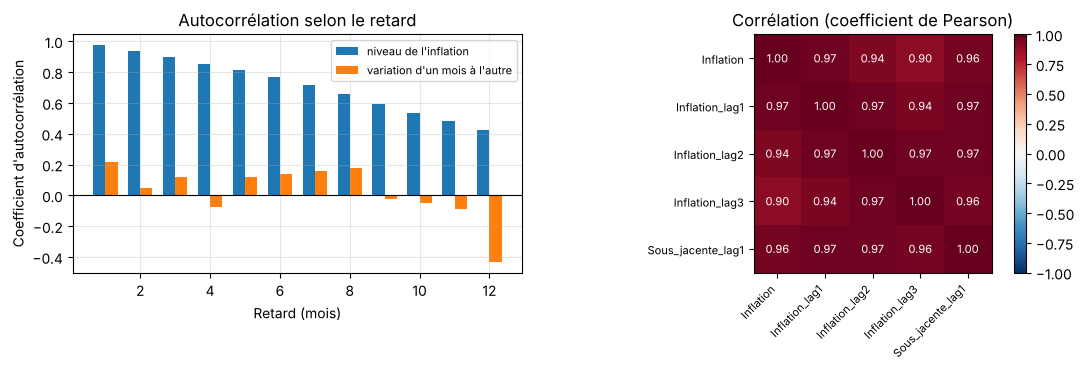

,corrélation avec Inflation
Inflation,1.00
Inflation_lag1,0.97
Inflation_lag2,0.94
Inflation_lag3,0.90
Sous_jacente_lag1,0.96


In [8]:
# ---------- Graphique 3 : autocorrélations et corrélations (apprentissage) ----------
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ks = np.arange(1, 13); l = .35
axes[0].bar(ks - l/2, acf_niveau, width=l, label="niveau de l'inflation", color="#1f77b4")
axes[0].bar(ks + l/2, acf_var, width=l, label="variation d'un mois à l'autre", color="#ff7f0e")
axes[0].axhline(0, color="black", lw=.8)
axes[0].set_title("Autocorrélation selon le retard"); axes[0].set_xlabel("Retard (mois)"); axes[0].set_ylabel("Coefficient d'autocorrélation"); axes[0].legend(fontsize=8)

tmp = exp[["Inflation"]].copy()
for k in (1, 2, 3): tmp[f"Inflation_lag{k}"] = exp["Inflation"].shift(k)
tmp["Sous_jacente_lag1"] = exp["Inflation_sous_jacente"].shift(1)
corr = tmp.dropna().corr()
im = axes[1].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
axes[1].set_xticks(range(len(corr))); axes[1].set_yticks(range(len(corr)))
axes[1].set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8); axes[1].set_yticklabels(corr.columns, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)): axes[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(corr.iloc[i, j]) > .6 else "black")
axes[1].grid(False); axes[1].set_title("Corrélation (coefficient de Pearson)")
plt.colorbar(im, ax=axes[1], fraction=.046)
plt.tight_layout(); sauver("g3_autocorrelation"); plt.show()
display(corr["Inflation"].round(2).to_frame("corrélation avec Inflation"))

**Interprétation du graphique 3.** L'autocorrélation du **niveau** est très forte (0,97 au retard 1, encore 0,42 au retard 12) : l'inflation d'un mois ressemble beaucoup à celle du mois précédent, en partie par construction (glissement sur 12 mois). L'autocorrélation de la **variation** d'un mois à l'autre est faible (0,21 au retard 1) et vaut −0,43 au retard 12, signe d'un effet de base : une hausse d'il y a un an tend à être suivie d'une baisse. Les variables explicatives sont très corrélées entre elles (0,94 à 0,97), ce qui justifie une régression régularisée. Conséquence pour la suite : la forte corrélation avec le mois précédent (0,97) ne prouve pas qu'on peut battre la marche aléatoire, car celle-ci l'exploite déjà intégralement ; un modèle n'a de valeur que s'il prédit la **variation**, nettement moins prévisible.

## 4. Préparation
- **Nettoyage** : décimales en virgule converties, dates reconstruites sur un index mensuel régulier (section 2). Pas d'imputation (0 % de manquants), pas d'encodage (variables numériques), pas de suppression de valeurs extrêmes (réelles).
- **Variables** : trois retards de l'inflation, un retard de l'inflation sous-jacente et un numéro de mois (`Tendance`). Deux jeux sont comparés en validation : **A** (avec `Tendance`) et **B** (sans). La tendance linéaire n'a pas de sens économique pour un taux et oblige le modèle à extrapoler hors de ce qu'il a vu.
- **Cible** : deux formes comparées en validation. « niveau » : Ridge prédit directement l'inflation du mois. « variation » : Ridge prédit `Inflation − Inflation_lag1`, puis on ajoute le mois précédent. La seconde est la plus naturelle ici : avec une forte régularisation elle revient à la marche aléatoire, au lieu de ramener la prévision vers la moyenne.
- **Fuites de données** : les retards utilisent `shift(k)` avec *k* > 0, l'alignement est vérifié par des `assert` ci-dessous (3 premières et dernières lignes affichées), l'exploration porte sur l'apprentissage seul. La mise à l'échelle (`StandardScaler`) est dans un `Pipeline`, donc réajustée sur chaque pli d'apprentissage. Elle est nécessaire : Ridge pénalise les coefficients, donc dépend de l'échelle des variables. La cible porte sur un seul mois, il n'y a donc pas de chevauchement et pas d'écart (gap) à prévoir entre apprentissage et test.

In [9]:
# ---------- Préparation : variables construites avec le PASSÉ uniquement ----------
feat = df.copy()
for k in (1, 2, 3):
    feat[f"Inflation_lag{k}"] = feat["Inflation"].shift(k)               # shift(k), k > 0 : valeur connue k mois avant
feat["Sous_jacente_lag1"] = feat["Inflation_sous_jacente"].shift(1)       # sous-jacente du mois précédent
feat["Tendance"] = np.arange(len(feat))                                   # numéro du mois (testée puis comparée en validation)
feat["Variation"] = feat["Inflation"] - feat["Inflation_lag1"]            # cible alternative : variation par rapport au mois précédent
feat = feat.dropna().reset_index(drop=True)                               # retire les 3 premiers mois (retards incomplets)

CIBLE = "Inflation"
VARS_A = ["Inflation_lag1", "Inflation_lag2", "Inflation_lag3", "Sous_jacente_lag1", "Tendance"]   # jeu A : version initiale
VARS_B = ["Inflation_lag1", "Inflation_lag2", "Inflation_lag3", "Sous_jacente_lag1"]                # jeu B : sans tendance

# Preuve d'alignement : pour chaque ligne, le retard k correspond bien à la valeur du mois (t − k)
serie = df.set_index("Mois")["Inflation"]; serie_sj = df.set_index("Mois")["Inflation_sous_jacente"]
for k in (1, 2, 3):
    attendu = feat["Mois"].apply(lambda t: serie[t - pd.DateOffset(months=k)])
    assert np.allclose(attendu.values, feat[f"Inflation_lag{k}"].values)
attendu_sj = feat["Mois"].apply(lambda t: serie_sj[t - pd.DateOffset(months=1)])
assert np.allclose(attendu_sj.values, feat["Sous_jacente_lag1"].values)
print("Alignement vérifié : aucune variable n'utilise une information postérieure à la date de prédiction.")
print("Table finale :", feat.shape)
cols = ["Mois", "Inflation", "Inflation_lag1", "Inflation_lag2", "Inflation_lag3", "Sous_jacente_lag1"]
display(feat[cols].head(4).round(2)); display(feat[cols].tail(3).round(2))
feat.to_csv(DOSSIER_PREP/"inflation_variables.csv", index=False)

Alignement vérifié : aucune variable n'utilise une information postérieure à la date de prédiction.
Table finale : (102, 9)


,Mois,Inflation,Inflation_lag1,Inflation_lag2,Inflation_lag3,Sous_jacente_lag1
0,2018-04-01,2.2,1.7,1.4,2.0,1.1
1,2018-05-01,2.4,2.2,1.7,1.4,1.2
2,2018-06-01,2.4,2.4,2.2,1.7,1.4
3,2018-07-01,1.9,2.4,2.4,2.2,1.5


,Mois,Inflation,Inflation_lag1,Inflation_lag2,Inflation_lag3,Sous_jacente_lag1
99,2026-07-01,-0.6,0.3,1.2,1.7,-0.2
100,2026-08-01,-0.3,-0.6,0.3,1.2,-0.3
101,2026-09-01,0.5,-0.3,-0.6,0.3,-0.1


In [10]:
# ---------- Découpage chronologique (sans mélange) ----------
ent = feat[feat["Mois"] < DEBUT_TEST].reset_index(drop=True)
test = feat[feat["Mois"] >= DEBUT_TEST].reset_index(drop=True)
print(f"Apprentissage : {ent['Mois'].min():%Y-%m} → {ent['Mois'].max():%Y-%m}  ({len(ent)} observations)")
print(f"Test          : {test['Mois'].min():%Y-%m} → {test['Mois'].max():%Y-%m}  ({len(test)} observations)")
assert ent["Mois"].max() < test["Mois"].min()

Apprentissage : 2018-04 → 2023-12  (69 observations)
Test          : 2024-01 → 2026-09  (33 observations)


## 5. Algorithme — Ridge (n° 2)

**Principe.** Ridge est une régression linéaire dont on pénalise la taille des coefficients. L'intuition : quand les variables sont très corrélées (ici les retards), les coefficients des moindres carrés deviennent instables ; la pénalité les stabilise en les rapprochant de 0. On résout :

$$\hat\beta = \arg\min_{\beta_0,\beta}\ \sum_{i=1}^{n}\big(y_i-\beta_0-x_i^{\top}\beta\big)^2+\alpha\sum_{j=1}^{p}\beta_j^{2}$$

où *n* est le nombre de mois d'apprentissage, *y_i* la cible du mois *i* (niveau ou variation de l'inflation), *x_i* le vecteur des *p* variables explicatives standardisées, β₀ l'ordonnée à l'origine (non pénalisée), β_j les coefficients et α ≥ 0 la force de la pénalité. Pour des variables centrées, la solution est $\hat\beta=(X^{\top}X+\alpha I)^{-1}X^{\top}y$.

**Paramètres appris** : β₀ et les β_j. **Hyperparamètres fixés par nous** : α (réglé en validation), le jeu de variables (A ou B, donc le nombre de retards), la forme de la cible, et `fit_intercept=True`.

**Effet attendu de α.** α petit : proche des moindres carrés, coefficients instables, risque de surapprentissage. α grand : coefficients proches de 0 et prévision proche d'une constante. Pour la cible « niveau », cette constante est la moyenne historique ; pour la cible « variation », c'est « le mois précédent plus une dérive moyenne », c'est-à-dire la marche aléatoire. **Le jeu de variables** joue aussi sur la complexité : le jeu A ajoute une tendance qui peut s'extrapoler mal.

**Pourquoi Ridge plutôt qu'une autre méthode du support ?** Une forêt aléatoire ou un gradient boosting (n° 6, 7) demandent plus de données qu'une soixantaine de mois et, étant des modèles à arbres, ne prédisent jamais hors de l'intervalle des valeurs d'apprentissage, alors que l'inflation du test (entre −0,8 % et 2,6 %) est dans un autre régime que celle de 2022-2023. Le Lasso (n° 3) est plausible, mais avec quatre variables très corrélées il en garderait une presque au hasard, alors que Ridge répartit le poids entre elles. La régression linéaire simple (n° 1) correspond à α → 0, ce que la validation permet de comparer.

## 6. Protocole expérimental
- **Découpage chronologique** (sans mélange) : apprentissage 2018-04 → 2023-12 (69 observations), test 2024-01 → 2026-09 (33 observations). Les dates de chaque pli de validation sont affichées ci-dessous.
- **Références** : (1) marche aléatoire, dernière valeur observée ; (2) moyenne historique de l'apprentissage. Elles sont évaluées sur les mêmes plis et sur le même test que Ridge.
- **Validation** : `TimeSeriesSplit` à 5 plis, sur l'apprentissage seulement (fenêtre qui s'agrandit ; le premier pli n'a que 14 mois d'apprentissage). **20 configurations** essayées : 2 jeux de variables × 2 formes de cible × 5 valeurs d'α (0,1 ; 1 ; 10 ; 100 ; 1000). La configuration de MAE de validation minimale est retenue automatiquement.
- **Métriques** : **MAE** (principale ; en points de %, lisible et peu sensible aux pics), **RMSE** (même unité, pénalise les grosses erreurs) et **R² hors échantillon par rapport à la marche aléatoire** = 1 − Σ(erreur du modèle)² / Σ(erreur de la marche aléatoire)² : positif si le modèle fait mieux que la référence, négatif sinon. Le R² classique n'est pas utilisé : pour une série qui change de régime, il est trompeur.
- **Test utilisé une seule fois**, après le choix de la configuration. Incertitude : moyenne ± écart-type sur les 5 plis, puis intervalle de bootstrap par blocs sur le test. Graine : 42 (Ridge est déterministe).

In [11]:
# ---------- Outils du protocole ----------
ALPHAS = [0.1, 1, 10, 100, 1000]            # 5 valeurs, échelle logarithmique
CIBLES = ["niveau", "variation"]            # ce que Ridge apprend à prédire
JEUX = {"A (avec tendance)": VARS_A, "B (sans tendance)": VARS_B}

def ajuster_predire(variables, forme_cible, alpha, d_ent, d_val):
    """Ajuste sur d_ent seulement (standardisation incluse), prédit le NIVEAU d'inflation sur d_ent et d_val.
    forme 'variation' : Ridge prédit (inflation_t − inflation_t-1) et on rajoute inflation_t-1."""
    y_ent = d_ent["Variation"] if forme_cible == "variation" else d_ent[CIBLE]
    modele = Pipeline([("echelle", StandardScaler()), ("ridge", Ridge(alpha=alpha))]).fit(d_ent[variables], y_ent)
    base_ent = d_ent["Inflation_lag1"].values if forme_cible == "variation" else 0.0
    base_val = d_val["Inflation_lag1"].values if forme_cible == "variation" else 0.0
    return modele.predict(d_ent[variables]) + base_ent, modele.predict(d_val[variables]) + base_val, modele

def mae(y, p): return mean_absolute_error(y, p)
def rmse(y, p): return mean_squared_error(y, p) ** 0.5

plis = list(TimeSeriesSplit(n_splits=5).split(ent))
for i, (a, b) in enumerate(plis, 1):
    print(f"Pli {i} : apprentissage {ent['Mois'][a[0]]:%Y-%m} → {ent['Mois'][a[-1]]:%Y-%m} ({len(a)} obs) | validation {ent['Mois'][b[0]]:%Y-%m} → {ent['Mois'][b[-1]]:%Y-%m} ({len(b)} obs)")

Pli 1 : apprentissage 2018-04 → 2019-05 (14 obs) | validation 2019-06 → 2020-04 (11 obs)
Pli 2 : apprentissage 2018-04 → 2020-04 (25 obs) | validation 2020-05 → 2021-03 (11 obs)
Pli 3 : apprentissage 2018-04 → 2021-03 (36 obs) | validation 2021-04 → 2022-02 (11 obs)
Pli 4 : apprentissage 2018-04 → 2022-02 (47 obs) | validation 2022-03 → 2023-01 (11 obs)
Pli 5 : apprentissage 2018-04 → 2023-01 (58 obs) | validation 2023-02 → 2023-12 (11 obs)


In [12]:
# ---------- Validation croisée temporelle (apprentissage seulement) ----------
# Références naïves évaluées sur les MÊMES plis
mae_rw, mae_moy = [], []
for a, b in plis:
    y_val = ent.loc[b, CIBLE].values
    mae_rw.append(mae(y_val, ent.loc[b, "Inflation_lag1"].values))          # marche aléatoire : dernière valeur observée
    mae_moy.append(mae(y_val, np.full(len(b), ent.loc[a, CIBLE].mean())))   # moyenne historique de l'apprentissage du pli

lignes = []
for nom_jeu, variables in JEUX.items():
    for forme in CIBLES:
        for alpha in ALPHAS:
            m_val, m_ent = [], []
            for a, b in plis:
                p_ent, p_val, _ = ajuster_predire(variables, forme, alpha, ent.loc[a], ent.loc[b])
                m_val.append(mae(ent.loc[b, CIBLE], p_val)); m_ent.append(mae(ent.loc[a, CIBLE], p_ent))
            lignes.append({"jeu": nom_jeu, "cible": forme, "alpha": alpha, "MAE_val_moy": np.mean(m_val),
                           "MAE_val_std": np.std(m_val), "MAE_ent_moy": np.mean(m_ent)})
cv = pd.DataFrame(lignes)
print(f"Configurations essayées en validation : {len(cv)}  ({len(JEUX)} jeux × {len(CIBLES)} cibles × {len(ALPHAS)} valeurs d'alpha)")
print(f"Références (MAE validation, moyenne ± écart-type sur 5 plis) : marche aléatoire = {np.mean(mae_rw):.3f} ± {np.std(mae_rw):.3f} | moyenne historique = {np.mean(mae_moy):.3f} ± {np.std(mae_moy):.3f}")
display(cv.pivot_table(index=["jeu", "cible"], columns="alpha", values="MAE_val_moy").round(3))

meilleure = cv.loc[cv["MAE_val_moy"].idxmin()]
JEU_CHOISI, FORME_CHOISIE, ALPHA_CHOISI = meilleure["jeu"], meilleure["cible"], float(meilleure["alpha"])
VARS_CHOISIES = JEUX[JEU_CHOISI]
print(f"\nConfiguration retenue (MAE de validation minimale) : jeu {JEU_CHOISI}, cible « {FORME_CHOISIE} », alpha = {ALPHA_CHOISI:g}")
print(f"MAE validation = {meilleure['MAE_val_moy']:.3f} ± {meilleure['MAE_val_std']:.3f}")
cv.to_csv(DOSSIER_PREP/"validation_croisee.csv", index=False)

Configurations essayées en validation : 20  (2 jeux × 2 cibles × 5 valeurs d'alpha)
Références (MAE validation, moyenne ± écart-type sur 5 plis) : marche aléatoire = 0.570 ± 0.128 | moyenne historique = 2.546 ± 2.226


alpha                        0.1     1.0     10.0    100.0   1000.0
jeu               cible                                            
A (avec tendance) niveau      0.916   0.977   1.098   1.302   2.180
                  variation   0.895   0.854   0.784   0.691   0.605
B (sans tendance) niveau      0.759   0.795   0.904   1.249   2.213
                  variation   0.753   0.744   0.722   0.685   0.604


Configuration retenue (MAE de validation minimale) : jeu B (sans tendance), cible « variation », alpha = 1000
MAE validation = 0.604 ± 0.158


**Interprétation (validation).** Aucune des 20 configurations ne bat la marche aléatoire en validation (MAE 0,570 ± 0,128). Pour la cible « variation », la MAE de validation diminue quand α augmente (jeu B : 0,753 pour α = 0,1, puis 0,744 ; 0,722 ; 0,685 et 0,604 pour α = 1000), c'est-à-dire quand le modèle se rapproche de la marche aléatoire. Pour la cible « niveau », l'erreur augmente avec α (jusqu'à 2,2), car le modèle tend vers la moyenne historique (MAE 2,546, très mauvaise référence). Le jeu B est meilleur que le jeu A (ou équivalent pour α = 1000) dans les deux formes de cible : la tendance ne sert à rien. Configuration retenue : jeu B, cible « variation », α = 1000 (MAE de validation 0,604 ± 0,158). Ce choix est en **bord de grille** ; aller plus loin ne changerait pas la conclusion, car α → ∞ donne exactement la marche aléatoire.

,alpha,MAE_ent_moy,MAE_val_moy,MAE_val_std
0,0.1,0.347,0.753,0.144
1,1.0,0.350,0.744,0.160
2,10.0,0.368,0.722,0.233
3,100.0,0.387,0.685,0.205
4,1000.0,0.401,0.604,0.158


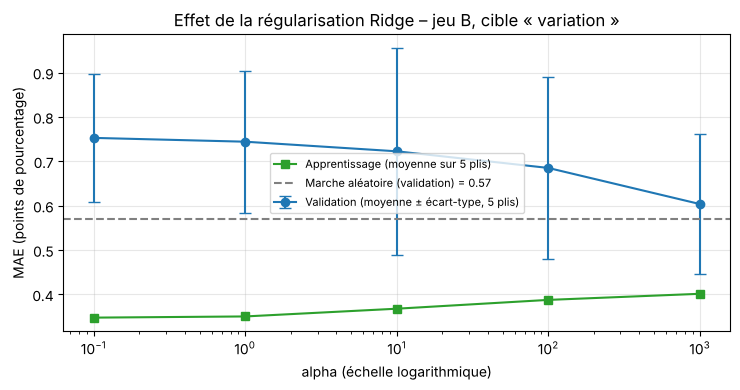

In [13]:
# ---------- Courbe de validation : erreur d'apprentissage vs validation selon alpha ----------
sel = cv[(cv["jeu"] == JEU_CHOISI) & (cv["cible"] == FORME_CHOISIE)]
display(sel[["alpha", "MAE_ent_moy", "MAE_val_moy", "MAE_val_std"]].round(3).reset_index(drop=True))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.errorbar(sel["alpha"], sel["MAE_val_moy"], yerr=sel["MAE_val_std"], marker="o", capsize=4, color="#1f77b4", label="Validation (moyenne ± écart-type, 5 plis)")
ax.plot(sel["alpha"], sel["MAE_ent_moy"], marker="s", color="#2ca02c", label="Apprentissage (moyenne sur 5 plis)")
ax.axhline(np.mean(mae_rw), color="grey", ls="--", label=f"Marche aléatoire (validation) = {np.mean(mae_rw):.2f}")
ax.set_xscale("log"); ax.set_xlabel("alpha (échelle logarithmique)"); ax.set_ylabel("MAE (points de pourcentage)")
ax.set_title(f"Effet de la régularisation Ridge – jeu {JEU_CHOISI[0]}, cible « {FORME_CHOISIE} »")
ax.legend(fontsize=8); plt.tight_layout(); sauver("g4_courbe_validation"); plt.show()

**Interprétation du graphique 4 (courbe de validation).** L'erreur d'apprentissage augmente légèrement avec α (0,347 → 0,401) tandis que l'erreur de validation diminue (0,753 → 0,604). Un faible α ajuste donc mieux le passé (0,347) mais généralise moins bien : c'est du surapprentissage, qui disparaît seulement quand le modèle se réduit presque à la marche aléatoire. L'écart-type de validation (0,14 à 0,23) est du même ordre que les différences entre configurations proches : on ne peut pas les départager finement.

## 7. Résultats
Le jeu de test est utilisé ici pour la première et unique fois.

In [14]:
# ---------- ÉVALUATION FINALE sur le test (utilisé une seule fois) ----------
p_ent, p_test, modele_final = ajuster_predire(VARS_CHOISIES, FORME_CHOISIE, ALPHA_CHOISI, ent, test)
y_test = test[CIBLE].values
p_rw = test["Inflation_lag1"].values                                   # marche aléatoire
p_moy = np.full(len(test), ent[CIBLE].mean())                           # moyenne historique (apprentissage)

def r2_oos(y, p, p_ref): return 1 - np.sum((y - p) ** 2) / np.sum((y - p_ref) ** 2)

resume = pd.DataFrame({
    "Modèle": ["Marche aléatoire (référence)", "Moyenne historique", f"Ridge (α={ALPHA_CHOISI:g})"],
    "MAE validation": [np.mean(mae_rw), np.mean(mae_moy), meilleure["MAE_val_moy"]],
    "MAE test": [mae(y_test, p_rw), mae(y_test, p_moy), mae(y_test, p_test)],
    "RMSE test": [rmse(y_test, p_rw), rmse(y_test, p_moy), rmse(y_test, p_test)],
    "R² hors échantillon vs marche aléatoire": [0.0, r2_oos(y_test, p_moy, p_rw), r2_oos(y_test, p_test, p_rw)],
})
resume["Variation de MAE vs marche aléatoire (%)"] = (resume["MAE test"] / resume.loc[0, "MAE test"] - 1) * 100
display(resume.round(3))

mae_ridge, mae_ref = mae(y_test, p_test), mae(y_test, p_rw)
reduction = (1 - mae_ridge / mae_ref) * 100
print(f"MAE apprentissage (modèle final) : {mae(ent[CIBLE], p_ent):.3f} | MAE test : {mae_ridge:.3f}")
print(f"Réduction de MAE par rapport à la marche aléatoire : {reduction:+.1f} %  (objectif : ≥ 15 %)")
print("OBJECTIF ATTEINT" if reduction >= 15 else "OBJECTIF NON ATTEINT")
print(f"Mois où le modèle fait mieux que la marche aléatoire : {int((np.abs(y_test-p_test) < np.abs(y_test-p_rw)).sum())} sur {len(y_test)}")
resume.to_csv(DOSSIER_PREP/"resultats_test.csv", index=False)

,Modèle,MAE validation,MAE test,RMSE test,R² hors échantillon vs marche aléatoire,Variation de MAE vs marche aléatoire (%)
0,Marche aléatoire (référence),0.570,0.597,0.766,0.000,0.000
1,Moyenne historique,2.546,2.139,2.295,-7.981,258.376
2,Ridge (α=1000),0.604,0.600,0.767,-0.004,0.582


MAE apprentissage (modèle final) : 0.519 | MAE test : 0.600
Réduction de MAE par rapport à la marche aléatoire : -0.6 %  (objectif : ≥ 15 %)
OBJECTIF NON ATTEINT
Mois où le modèle fait mieux que la marche aléatoire : 14 sur 33


In [15]:
# ---------- Incertitude et stabilité ----------
# (a) Bootstrap par blocs (longueur 3) du gain de perte absolue : |erreur marche aléatoire| − |erreur Ridge|
rng = np.random.default_rng(GRAINE)
d = np.abs(y_test - p_rw) - np.abs(y_test - p_test)       # > 0 : le modèle est meilleur ce mois-là
n, L, B = len(d), 3, 4000
moyennes = []
for _ in range(B):
    debuts = rng.integers(0, n - L + 1, size=int(np.ceil(n / L)))
    ech = np.concatenate([d[s:s + L] for s in debuts])[:n]
    moyennes.append(ech.mean())
bas, haut = np.percentile(moyennes, [2.5, 97.5])
print(f"Gain moyen de MAE du modèle sur la marche aléatoire : {d.mean():+.3f} point | intervalle à 95 % (bootstrap par blocs) : [{bas:+.3f} ; {haut:+.3f}]")

# (b) Stabilité sur deux sous-périodes du test
moitie = len(test) // 2
for nom, sl in [(f"{test['Mois'][0]:%Y-%m} → {test['Mois'][moitie-1]:%Y-%m}", slice(0, moitie)),
                (f"{test['Mois'][moitie]:%Y-%m} → {test['Mois'].iloc[-1]:%Y-%m}", slice(moitie, None))]:
    print(f"Sous-période {nom} ({len(y_test[sl])} mois) : MAE marche aléatoire = {mae(y_test[sl], p_rw[sl]):.3f} | MAE Ridge = {mae(y_test[sl], p_test[sl]):.3f}")

Gain moyen de MAE du modèle sur la marche aléatoire : -0.003 point | intervalle à 95 % (bootstrap par blocs) : [-0.016 ; +0.007]
Sous-période 2024-01 → 2025-04 (16 mois) : MAE marche aléatoire = 0.744 | MAE Ridge = 0.746
Sous-période 2025-05 → 2026-09 (17 mois) : MAE marche aléatoire = 0.459 | MAE Ridge = 0.464


**Interprétation (résultats sur le test).** Ridge (α = 1000) obtient une MAE de 0,600 contre 0,597 pour la marche aléatoire, soit +0,6 % (RMSE 0,767 contre 0,766 ; R² hors échantillon de −0,004). La moyenne historique est très mauvaise (MAE 2,139). **L'objectif (réduction d'au moins 15 %) n'est pas atteint** : le gain est de −0,6 %. Le modèle fait mieux que la marche aléatoire 14 mois sur 33 seulement. L'intervalle de bootstrap à 95 % du gain moyen, [−0,016 ; +0,007] point, contient 0 : la différence est indiscernable de zéro. Les deux sous-périodes donnent le même verdict (2024-01 → 2025-04 : 0,744 contre 0,746 ; 2025-05 → 2026-09 : 0,459 contre 0,464), donc le résultat est stable dans le temps. Surapprentissage : la MAE d'apprentissage (0,519) est inférieure à celle du test (0,600), mais les deux périodes ne sont pas comparables (régimes différents) ; avec des coefficients presque nuls (voir plus bas), le modèle est trop peu flexible pour mémoriser le passé.

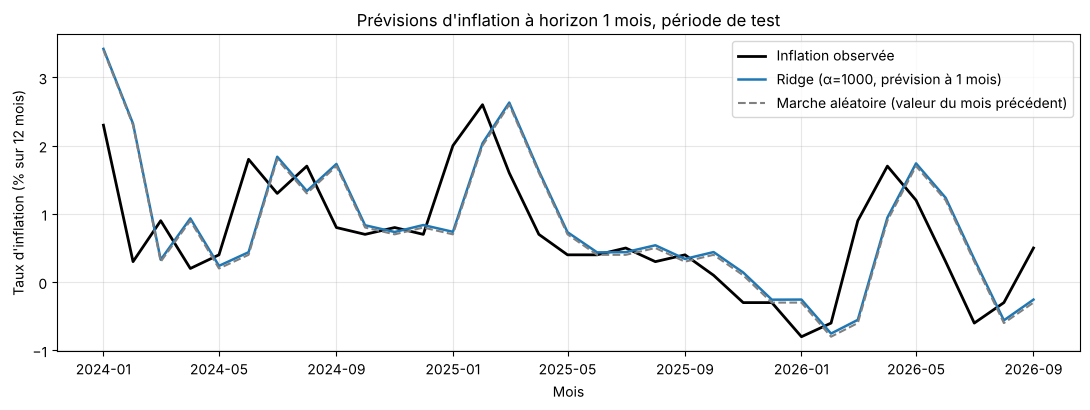

In [16]:
# ---------- Graphique 5 : prévisions sur la période de test ----------
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(test["Mois"], y_test, color="black", lw=2, label="Inflation observée")
ax.plot(test["Mois"], p_test, color="#1f77b4", lw=1.8, label=f"Ridge (α={ALPHA_CHOISI:g}, prévision à 1 mois)")
ax.plot(test["Mois"], p_rw, color="grey", ls="--", lw=1.5, label="Marche aléatoire (valeur du mois précédent)")
ax.set_title("Prévisions d'inflation à horizon 1 mois, période de test"); ax.set_xlabel("Mois"); ax.set_ylabel("Taux d'inflation (% sur 12 mois)")
ax.legend(); plt.tight_layout(); sauver("g5_previsions_test"); plt.show()

**Interprétation du graphique 5.** La prévision de Ridge est pratiquement superposée à celle de la marche aléatoire : le modèle recopie le mois précédent avec un décalage d'un mois. Il rate donc tous les retournements : la forte baisse de janvier à février 2024 (2,3 % puis 0,3 %), les rebonds de 2025 et de 2026.

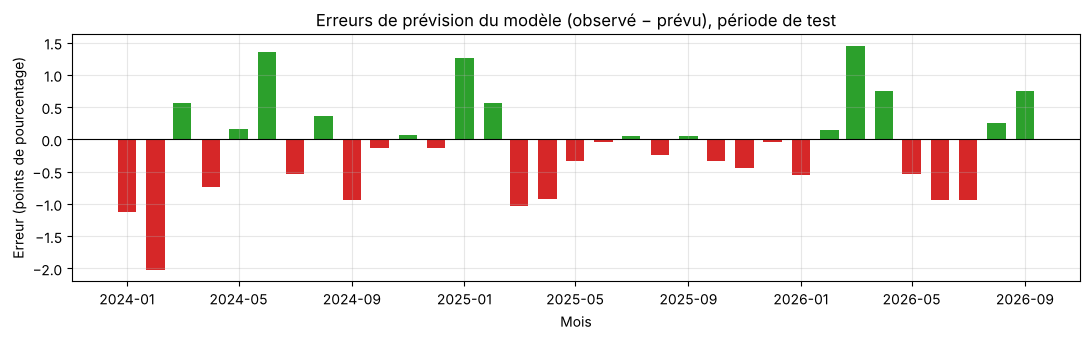

Les 6 plus grosses erreurs du modèle :


,Mois,Observé,Ridge,Marche aléatoire,Erreur Ridge,Erreur marche aléatoire
1,2024-02,0.3,2.32,2.3,-2.02,-2.0
26,2026-03,0.9,-0.55,-0.6,1.45,1.5
5,2024-06,1.8,0.44,0.4,1.36,1.4
12,2025-01,2.0,0.74,0.7,1.26,1.3
0,2024-01,2.3,3.42,3.4,-1.12,-1.1
14,2025-03,1.6,2.63,2.6,-1.03,-1.0


Biais moyen (observé − prévu) : -0.125 | autocorrélation d'ordre 1 des erreurs : 0.15


In [17]:
# ---------- Analyse des erreurs ----------
residus = y_test - p_test
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(test["Mois"], residus, width=20, color=np.where(residus > 0, "#2ca02c", "#d62728"))
ax.axhline(0, color="black", lw=.8)
ax.set_title("Erreurs de prévision du modèle (observé − prévu), période de test")
ax.set_xlabel("Mois"); ax.set_ylabel("Erreur (points de pourcentage)")
plt.tight_layout(); sauver("g6_residus"); plt.show()

erreurs = pd.DataFrame({"Mois": test["Mois"].dt.strftime("%Y-%m"), "Observé": y_test, "Ridge": p_test, "Marche aléatoire": p_rw,
                        "Erreur Ridge": residus, "Erreur marche aléatoire": y_test - p_rw})
print("Les 6 plus grosses erreurs du modèle :")
display(erreurs.reindex(erreurs["Erreur Ridge"].abs().sort_values(ascending=False).index).head(6).round(2))
print(f"Biais moyen (observé − prévu) : {residus.mean():+.3f} | autocorrélation d'ordre 1 des erreurs : {pd.Series(residus).autocorr(1):.2f}")

**Analyse des erreurs.** Les plus grosses erreurs sont les retournements brutaux : février 2024 (observé 0,3 %, prévu 2,32 %, erreur −2,02), mars 2026 (0,9 % observé, −0,55 % prévu, +1,45), juin 2024 (+1,36), janvier 2025 (+1,26). La marche aléatoire fait pratiquement les mêmes erreurs (−2,0 ; +1,5 ; +1,4 ; +1,3). Ces sauts ne se lisent pas dans les valeurs passées de l'inflation ; une explication plausible, **non vérifiée** faute d'indice mensuel dans le fichier, est l'effet de base (l'autocorrélation de la variation au retard 12 est de −0,43 sur l'apprentissage). Le biais moyen est faible (−0,125 : le modèle surestime un peu) et les erreurs sont peu autocorrélées (0,15) : il ne reste pas de structure simple dans les erreurs.

In [18]:
# ---------- Interprétation prudente des variables ----------
coefs = pd.Series(modele_final.named_steps["ridge"].coef_, index=VARS_CHOISIES).sort_values(key=abs, ascending=False)
print(f"Coefficients Ridge (variables standardisées ; cible apprise : « {FORME_CHOISIE} ») :")
display(coefs.round(3).to_frame("coefficient"))

# Importance par permutation (sur le test, a posteriori : aucun réglage n'en découle), 30 répétitions.
# On permute les variables d'ENTRÉE du modèle ; le point d'ancrage (inflation du mois précédent) reste celui du vrai mois.
rng = np.random.default_rng(GRAINE)
ancre = test["Inflation_lag1"].values if FORME_CHOISIE == "variation" else 0.0
base = mae(y_test, modele_final.predict(test[VARS_CHOISIES]) + ancre); imp = {}
for v in VARS_CHOISIES:
    pertes = []
    for _ in range(30):
        Xp = test[VARS_CHOISIES].copy(); Xp[v] = rng.permutation(Xp[v].values)
        pertes.append(mae(y_test, modele_final.predict(Xp) + ancre) - base)
    imp[v] = (np.mean(pertes), np.std(pertes))
imp = pd.DataFrame(imp, index=["Hausse de MAE (moyenne)", "écart-type"]).T.sort_values("Hausse de MAE (moyenne)", ascending=False)
display(imp.round(4))

Coefficients Ridge (variables standardisées ; cible apprise : « variation ») :


,coefficient
Inflation_lag3,-0.007
Inflation_lag2,-0.006
Inflation_lag1,-0.004
Sous_jacente_lag1,-0.002


,Hausse de MAE (moyenne),écart-type
Inflation_lag2,0.0008,0.0005
Inflation_lag3,0.0006,0.0005
Inflation_lag1,0.0005,0.0002
Sous_jacente_lag1,0.0001,0.0001


**Interprétation prudente des variables.** À cause de la forte pénalité (α = 1000), les coefficients sont presque nuls (de −0,002 à −0,007 sur la variation, en variables standardisées) ; l'importance par permutation est inférieure à 0,001 point de MAE pour chaque variable. Aucune variable n'apporte donc d'information utilisable par le modèle. Le signe négatif des quatre coefficients est cohérent avec un retour vers la moyenne (inflation haute → variation prévue plus basse), mais ces valeurs sont trop faibles pour être interprétées, et il s'agit de corrélations dans le temps, pas de relations de cause à effet.

In [19]:
# ---------- Illustration d'usage sur 4 mois non utilisés pour l'apprentissage ----------
mois_choisis = ["2024-01", "2024-09", "2025-06", "2026-04"]      # choisis à l'avance, espacés dans le test
vitrine = test.assign(cle=test["Mois"].dt.strftime("%Y-%m")).set_index("cle").loc[mois_choisis]
_, p_vit, _ = ajuster_predire(VARS_CHOISIES, FORME_CHOISIE, ALPHA_CHOISI, ent, vitrine.reset_index(drop=True))
tab = pd.DataFrame({"Inflation t−1": vitrine["Inflation_lag1"], "Inflation t−2": vitrine["Inflation_lag2"],
                    "Sous-jacente t−1": vitrine["Sous_jacente_lag1"], "Prévision Ridge": p_vit,
                    "Marche aléatoire": vitrine["Inflation_lag1"], "Valeur réelle": vitrine["Inflation"]})
tab["Erreur Ridge"] = tab["Valeur réelle"] - tab["Prévision Ridge"]; tab["Erreur marche aléatoire"] = tab["Valeur réelle"] - tab["Marche aléatoire"]
display(tab.round(2))

,Inflation t−1,Inflation t−2,Sous-jacente t−1,Prévision Ridge,Marche aléatoire,Valeur réelle,Erreur Ridge,Erreur marche aléatoire
cle,,,,,,,,
2024-01,3.4,3.6,3.05,3.42,3.4,2.3,-1.12,-1.1
2024-09,1.7,1.3,2.56,1.73,1.7,0.8,-0.93,-0.9
2025-06,0.4,0.7,0.84,0.44,0.4,0.4,-0.04,0.0
2026-04,0.9,-0.6,-0.83,0.95,0.9,1.7,0.75,0.8


**Illustration sur 4 mois non utilisés pour l'apprentissage.** En janvier 2024, le modèle prévoit 3,42 % (inflation de décembre : 3,4 %) alors que l'inflation tombe à 2,3 % (erreur −1,12). En septembre 2024, il prévoit 1,73 % pour 0,8 % observé (−0,93). En juin 2025, quand l'inflation est stable, la prévision est quasi exacte (0,44 % contre 0,4 %). En avril 2026, il prévoit 0,95 % alors que l'inflation rebondit à 1,7 % (+0,75). Le modèle est donc correct quand l'inflation est stable, mais incapable d'anticiper un changement de direction, exactement comme la marche aléatoire.

## 8. Analyse critique
**Limites.**
- La marche aléatoire est une référence très forte pour un taux en glissement annuel (autocorrélation de 0,97) : il faudrait des informations nouvelles, absentes du fichier, pour la battre à un mois.
- Peu de données : 69 mois d'apprentissage, un premier pli de validation de 14 mois, un test de 33 mois (intervalle de bootstrap large).
- Changement de régime : l'apprentissage contient le choc de 2022-2023, le test une inflation faible ; la validation croisée est dominée par cette période de flambée.
- **Le test n'est plus strictement vierge** : une version préliminaire du travail (cible en niveau, variable de tendance) avait déjà été évaluée sur la même période avant que la démarche soit reprise. Ce choix de méthode a ensuite été fait en validation, mais cela peut flatter légèrement les résultats.
- α retenu en bord de grille (1000) : le modèle sélectionné se confond avec la marche aléatoire.
- Données : précision hétérogène, pas d'indice mensuel, pas d'information sur les révisions ni sur la base de l'indice (voir section 2).

**Pistes d'amélioration.**
1. Récupérer l'indice des prix mensuel pour construire les variations d'un mois à l'autre et une variable « variation d'il y a 12 mois » qui traite l'effet de base (autocorrélation de −0,43 au retard 12) ; c'est l'explication la plus plausible des gros retournements, à vérifier.
2. Ajouter des variables extérieures : prix des carburants et du pétrole, prix des produits alimentaires volatils, taux de change.
3. Passer à une évaluation par fenêtre glissante (rolling origin) et tester d'autres horizons (3 et 6 mois), où la marche aléatoire est peut-être moins dominante (hypothèse à vérifier).

## 9. Conclusion
**Non** : sur cette période et avec ces variables, Ridge ne prévoit pas l'inflation marocaine à un mois mieux que la marche aléatoire. Sa MAE sur le test est de 0,600 point contre 0,597 (+0,6 %), loin de l'objectif d'une réduction d'au moins 15 %, et l'intervalle de bootstrap du gain contient 0. La validation sélectionne d'elle-même la plus forte régularisation, ce qui ramène Ridge à la marche aléatoire : les retards de l'inflation et de l'inflation sous-jacente du mois précédent n'apportent pas d'information supplémentaire exploitable. Pour une prévision à un mois, « le mois prochain ressemblera à ce mois-ci » reste la meilleure règle simple ; un gain demanderait de nouvelles informations, par exemple l'effet de base.

## 10. Références et reproduction
**Références**
- Bank Al-Maghrib, Statistiques, Prix (inflation et inflation sous-jacente) : https://www.bkam.ma/Statistiques/Prix
- Documentation scikit-learn : `Ridge`, `StandardScaler`, `Pipeline`, `TimeSeriesSplit` (https://scikit-learn.org)
- Support de cours `Tp_ML.ipynb` (algorithme n° 2, Ridge) et énoncé de l'examen (sujet F3)

**Reproduction**
1. Cloner le dépôt : https://github.com/salmane-khaoulaencg-a11y/23009361-Salmane-Khaoula-G3-FIN
2. Python 3.10 ou plus récent ; `pip install -r requirements.txt`.
3. Vérifier que `data/raw/BKAM Inflation et inflation sous jacente.xlsx` est présent.
4. Ouvrir `notebooks/projet_F3.ipynb`, puis « Redémarrer et tout exécuter » (environ 1 minute). Les figures sont écrites dans `figures/`, les tables dans `data/processed/`. Les résultats sont déterministes (graine 42).

## Déclaration des ressources et outils d'IA

| Outil ou ressource | Version ou date | Usage précis | Parties concernées | Vérification effectuée |
|---|---|---|---|---|
| Assistant d'IA (Grok) | novembre 2026 | Structure du notebook initial, suggestions de code et de rédaction | Première version du notebook | Code relu, testé et adapté |
| Assistant d'IA (Claude, Anthropic) | 17/11/2026 | Correction du notebook selon l'énoncé : restructuration en dix sections, réécriture du code (pipeline, validation temporelle, graphiques, analyse des erreurs) et des commentaires | Ensemble du notebook | Notebook réexécuté de bout en bout ; chiffres des commentaires comparés aux sorties |
| Documentation scikit-learn | version installée (voir en tête de notebook) | Paramètres de `Ridge`, `TimeSeriesSplit`, `Pipeline` | Sections 4 à 6 | Exemples officiels consultés |